# I de Moran global con k vecinos más cercanos (k = 8)

El **índice de Moran global** ($I$) resume si los municipios vecinos tienden a presentar tasas semejantes. Un valor positivo indica asociación entre tasas parecidas; uno negativo, contraste entre vecinos. El valor se interpreta según la matriz de vecindad elegida y se compara con permutaciones para evaluar si el patrón observado sería habitual al reasignar las tasas al azar. El índice no identifica por sí solo municipios concretos ni explica la causa del patrón.

Esta primera iteración calcula **a mano, paso a paso** la autocorrelación espacial global de la tasa anual de notificaciones de varicela por 100.000 habitantes en los municipios de Colombia durante **2025**. Usamos los datos ya preparados en este repositorio.

La pregunta es: **¿los municipios cercanos tienden a tener tasas parecidas?** El resultado describe asociación espacial en este año y con esta definición de vecindad; no demuestra una causa.

**Ruta de lectura:** datos → ubicación de municipios → distancias → vecinos → matriz de pesos → tasas centradas → I de Moran → permutaciones → interpretación.

## 1. Preparación y decisiones

- **Unidad:** municipio, identificado por su código DIVIPOLA. Se excluyen áreas no municipalizadas y la categoría «Isla», que figuran por separado en el GeoJSON.
- **Variable $x_i$:** tasa anual de **notificaciones**, no incidencia clínica, por 100.000 habitantes. El CSV la calcula con los casos y la población del año.
- **Año:** 2025, para tener una sola observación por municipio. Se puede cambiar la constante `ANIO` por otro año entre 2008 y 2025.
- **Lugar representativo:** un punto dentro de cada polígono municipal. Para un municipio con varias partes, esta aproximación puede diferir de su centro poblado.
- **Distancia:** gran círculo (haversine) entre esos puntos, en kilómetros. No representa tiempo de viaje ni contigüidad entre polígonos.
- **Vecindad:** los 8 municipios más próximos a cada municipio, sin incluirlo a él mismo. La relación puede ser dirigida: A puede elegir a B sin que B elija a A.

El notebook busca la raíz del repositorio si se abre desde la raíz o desde la carpeta `notebooks/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import shape

ANIO = 2025
K = 8
RAIZ = Path.cwd()
if not (RAIZ / "docs/data_processed").is_dir():
    RAIZ = RAIZ.parent
assert (RAIZ / "docs/data_processed").is_dir(), "Ejecuta desde la raíz del repositorio o notebooks/"

RUTA_TASAS = RAIZ / "docs/data_processed/heterogeneidad_espacial/spatial_series_2008_2025.csv"
RUTA_GEOMETRIAS = RAIZ / "docs/data_processed/cartografia/municipal_boundaries_dane.geojson"

## 2. Cargar y alinear las observaciones

Un mismo índice $i$ debe representar **el mismo municipio** en el vector de tasas, las coordenadas y las filas y columnas de la matriz de pesos. Conservar DIVIPOLA como texto evita perder ceros iniciales. El archivo de tasas contiene también periodos agregados: seleccionamos solamente el año indicado.

Usamos `representative_point()` para obtener un punto interior de cada geometría; el centroide geométrico podría quedar fuera de algunos polígonos. Conservamos únicamente las filas con tasa y coordenadas válidas. El resumen permite ver cuántas observaciones entran al cálculo.

In [2]:
tasas = pd.read_csv(RUTA_TASAS, dtype={"period": str, "code": str})
tasas = tasas.loc[tasas["period"] == str(ANIO), ["code", "rate_per_100k"]].copy()
tasas["rate_per_100k"] = pd.to_numeric(tasas["rate_per_100k"], errors="coerce")
assert not tasas["code"].duplicated().any(), "Hay códigos repetidos en las tasas del año"

with RUTA_GEOMETRIAS.open(encoding="utf-8") as archivo:
    geojson = json.load(archivo)

ubicaciones = []
for feature in geojson["features"]:
    propiedades = feature["properties"]
    if propiedades["kind"] != "MUNICIPIO":
        continue
    punto = shape(feature["geometry"]).representative_point()
    ubicaciones.append({
        "code": propiedades["code"],
        "municipio": propiedades["name"],
        "lat": punto.y,
        "lon": punto.x,
    })
ubicaciones = pd.DataFrame(ubicaciones)
assert not ubicaciones["code"].duplicated().any(), "Hay códigos repetidos en las geometrías"

datos = ubicaciones.merge(tasas, on="code", how="left", validate="one_to_one")
sin_tasa = datos["rate_per_100k"].isna().sum()
datos = datos.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["lat", "lon", "rate_per_100k"]
).sort_values("code").reset_index(drop=True)

print(f"Municipios en el GeoJSON: {len(ubicaciones)}")
print(f"Municipios sin tasa para {ANIO}: {sin_tasa}")
print(f"Municipios usados: {len(datos)}")
display(datos.head())

Municipios en el GeoJSON: 1103
Municipios sin tasa para 2025: 0
Municipios usados: 1103


,code,municipio,lat,lon,rate_per_100k
0,05001,MEDELLÍN,6.26755,-75.602158,53.1573
1,05002,ABEJORRAL,5.80285,-75.430621,0.0000
2,05004,ABRIAQUÍ,6.62970,-76.083433,35.6252
3,05021,ALEJANDRÍA,6.35665,-75.099605,151.3718
4,05030,AMAGÁ,6.03475,-75.704151,12.1736


## 3. De coordenadas a distancias

Calculamos la distancia entre **cada par** de puntos con la fórmula haversine. $D_{ij}$ expresa kilómetros entre el municipio $i$ y el municipio $j$. Para impedir que una unidad se elija a sí misma, ponemos infinito en la diagonal antes de buscar los vecinos.

Llamamos $n$ al número de municipios que quedan tras alinear tasas y geometrías; en el código, `n = len(datos)`. Los índices $i$ y $j$ recorren esos $n$ municipios.

Esta matriz de distancias es simétrica, aunque la selección de los ocho vecinos más cercanos no tiene por qué serlo.

In [3]:
n = len(datos)
assert n > K, "Se necesitan más municipios que vecinos"
lat = np.radians(datos["lat"].to_numpy())
lon = np.radians(datos["lon"].to_numpy())
dlat = lat[:, None] - lat[None, :]
dlon = lon[:, None] - lon[None, :]
a = np.sin(dlat / 2) ** 2 + (
    np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2
)
distancias = 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
np.fill_diagonal(distancias, np.inf)

print("Distancias desde el primer municipio (km):")
display(pd.DataFrame({
    "municipio": datos["municipio"].iloc[1:6].to_numpy(),
    "distancia_km": distancias[0, 1:6].round(1),
}))

Distancias desde el primer municipio (km):


,municipio,distancia_km
0,ABEJORRAL,55.0
1,ABRIAQUÍ,66.7
2,ALEJANDRÍA,56.4
3,AMAGÁ,28.2
4,AMALFI,110.3


## 4. Elegir k = 8 vecinos y formar $W$

Ordenamos cada fila de la matriz de distancias y tomamos sus ocho índices más cercanos. Llamamos $W=(w_{ij})$ a la matriz de pesos de tamaño $n\times n$: $w_{ij}$ representa el peso que el municipio $i$ asigna al municipio $j$. Definimos:

$$
w_{ij} =
\begin{cases}
1/8 & \text{si } j \text{ es uno de los 8 vecinos de } i,\\
0 & \text{en otro caso.}
\end{cases}
$$

Es una matriz **binaria antes de normalizar** y **normalizada por fila después**: cada fila suma 1. La diagonal vale 0. Si dos distancias empatan exactamente, el orden de códigos DIVIPOLA (establecido arriba) determina cuál queda primero.

$S_0=\sum_{i=1}^{n}\sum_{j=1}^{n}w_{ij}$ es la suma de todos los pesos de $W$. Como cada una de las $n$ filas suma 1, aquí $S_0=n$; aun así, lo calculamos explícitamente para usarlo en la fórmula general de Moran.

In [4]:
vecinos = np.argsort(distancias, axis=1, kind="stable")[:, :K]
W = np.zeros((n, n), dtype=float)
W[np.arange(n)[:, None], vecinos] = 1.0 / K
S0 = W.sum()

assert np.allclose(W.sum(axis=1), 1)
assert np.all(np.diag(W) == 0)
print(f"Dimensiones de W: {W.shape}; S0 = {S0:.0f}")
print(f"Pares dirigidos sin reciprocidad: {np.count_nonzero((W > 0) & (W.T == 0))}")

i = 0
display(pd.DataFrame({
    "origen": datos.loc[i, "municipio"],
    "vecino": datos.loc[vecinos[i], "municipio"].to_numpy(),
    "distancia_km": distancias[i, vecinos[i]].round(1),
    "peso": W[i, vecinos[i]],
}))

Dimensiones de W: (1103, 1103); S0 = 1103
Pares dirigidos sin reciprocidad: 1936


,origen,vecino,distancia_km,peso
0,MEDELLÍN,ITAGÜÍ,10.2,0.125
1,MEDELLÍN,BELLO,11.1,0.125
2,MEDELLÍN,ENVIGADO,14.1,0.125
3,MEDELLÍN,SABANETA,14.4,0.125
4,MEDELLÍN,LA ESTRELLA,15.2,0.125
5,MEDELLÍN,COPACABANA,15.3,0.125
6,MEDELLÍN,GUARNE,17.7,0.125
7,MEDELLÍN,HELICONIA,17.9,0.125


## 5. Centrar las tasas y calcular el rezago espacial

Sea $x_i$ la tasa del municipio $i$. Definimos la media de los $n$ municipios incluidos, sin ponderar por población, y la desviación de cada tasa respecto de esa media:

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i, \qquad z_i=x_i-\bar{x}, \qquad z=(z_1,\ldots,z_n)^\mathsf{T}.
$$

La matriz de pesos $W$ tiene $n$ filas y $n$ columnas. Su fila $i$ es el **vector fila de pesos** $\mathbf{w}_i=(w_{i1},w_{i2},\ldots,w_{in})$, donde $w_{ij}$ es el peso asignado por $i$ al municipio $j$ y $w_{ii}=0$. El vector columna $z$ contiene las $n$ desviaciones. La operación matricial completa es:

$$
Wz=
\begin{pmatrix}
w_{11} & w_{12} & \cdots & w_{1n} \\
w_{21} & w_{22} & \cdots & w_{2n} \\
\vdots & \vdots & \ddots & \vdots \\
w_{n1} & w_{n2} & \cdots & w_{nn}
\end{pmatrix}
\begin{pmatrix}z_1 \\ z_2 \\ \vdots \\ z_n\end{pmatrix}
=
\begin{pmatrix}
(Wz)_{1} \\
(Wz)_{2} \\
\vdots \\
(Wz)_{n}
\end{pmatrix}.
$$

El **rezago espacial** del municipio $i$ es el componente $i$ de ese vector: el producto de su fila de pesos por $z$.

$$
(Wz)_i=\sum_{j=1}^{n}w_{ij}z_j.
$$

Como los ocho pesos no nulos de cada fila valen $1/8$, $(Wz)_i$ es el **promedio de las desviaciones** de los ocho vecinos de $i$.

Un valor positivo de $z_i$ significa tasa municipal por encima de la media; un $(Wz)_i$ positivo significa que sus vecinos, en promedio, también están por encima.

In [5]:
x = datos["rate_per_100k"].to_numpy(dtype=float)
media = x.mean()
z = x - media
rezago = W @ z
assert np.isfinite(x).all()
assert np.isclose(z.sum(), 0)
assert np.dot(z, z) > 0, "Moran no se define si todas las tasas son iguales"

print(f"Tasa media municipal: {media:.2f} por 100.000")
display(pd.DataFrame({
    "municipio": datos["municipio"].head(),
    "tasa": x[:5],
    "desviacion_z": z[:5],
    "rezago_Wz": rezago[:5],
}).round(2))

Tasa media municipal: 44.45 por 100.000


,municipio,tasa,desviacion_z,rezago_Wz
0,MEDELLÍN,53.16,8.70,-10.10
1,ABEJORRAL,0.00,-44.45,-19.41
2,ABRIAQUÍ,35.63,-8.83,5.79
3,ALEJANDRÍA,151.37,106.92,-13.17
4,AMAGÁ,12.17,-32.28,-29.47


## 6. Sustituir los términos en la fórmula de Moran

La I de Moran global es:

$$
I = \frac{n}{S_0}
    \frac{\sum_i\sum_j w_{ij}(x_i-\bar{x})(x_j-\bar{x})}
         {\sum_i(x_i-\bar{x})^2}
  = \frac{n}{S_0}\frac{z^\mathsf{T}Wz}{z^\mathsf{T}z}.
$$

El **numerador** reúne productos de desviaciones entre vecinos: pares con desviaciones del mismo signo aportan positivo. El **denominador** mide la variación total de las tasas. Como cada fila de $W$ suma 1, aquí $S_0=n$ y el primer factor vale 1. Mantenerlo visible facilita cambiar la convención de pesos más adelante.

En términos generales, $I>0$ sugiere semejanza entre vecinos, $I<0$ contraste entre vecinos. Su magnitud y su significación dependen de los datos y de la matriz elegida; **no debe interpretarse automáticamente como una correlación limitada a [-1, 1]**.

In [6]:
numerador = np.sum(z * rezago)  # Equivale a sum_i sum_j w_ij z_i z_j
denominador = np.sum(z ** 2)
factor = n / S0
I_observada = factor * numerador / denominador

print(f"n = {n}; S0 = {S0:.1f}; n/S0 = {factor:.3f}")
print(f"Numerador = {numerador:.2f}")
print(f"Denominador = {denominador:.2f}")
print(f"I de Moran observada = {I_observada:.4f}")

n = 1103; S0 = 1103.0; n/S0 = 1.000
Numerador = 423179.20
Denominador = 2927874.34
I de Moran observada = 0.1445


## 7. Visualizar el patrón

Cada punto representa un municipio: eje horizontal, su desviación respecto de la tasa media; eje vertical, el promedio de las desviaciones de sus vecinos. Con pesos normalizados por fila, la pendiente de la recta que pasa por el origen es exactamente la I calculada arriba. Unos pocos municipios con tasas extremas pueden influir mucho en la pendiente.

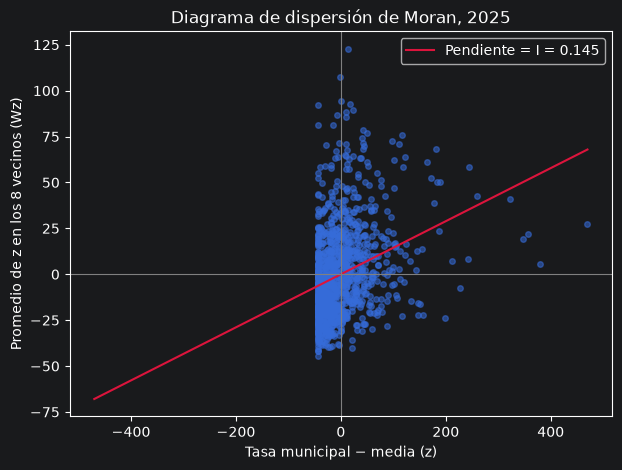

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(z, rezago, s=16, alpha=0.55)
lim = np.max(np.abs(z))
linea = np.array([-lim, lim])
ax.plot(linea, I_observada * linea, color="crimson",
        label=f"Pendiente = I = {I_observada:.3f}")
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set(xlabel="Tasa municipal − media (z)",
       ylabel="Promedio de z en los 8 vecinos (Wz)",
       title=f"Diagrama de dispersión de Moran, {ANIO}")
ax.legend()
plt.show()

## 8. Comparar con permutaciones

Para explorar si una I positiva podría aparecer por azar **manteniendo las tasas y $W$ fijas**, reubicamos aleatoriamente las tasas entre municipios 999 veces. En cada permutación recalculamos I. La semilla hace reproducible el ejemplo.

Como la hipótesis didáctica aquí es **autocorrelación positiva**, contamos valores permutados $\ge I_{obs}$. Sumamos 1 al numerador y al denominador para incluir el orden observado. Este valor p es condicional a la matriz, al conjunto de municipios y al procedimiento de permutación; no corrige por haber explorado varios años o varias decisiones analíticas.

Bajo permutación aleatoria, la referencia teórica usual para la media de I es $-1/(n-1)$.

I observada: 0.1445
Media de las permutaciones: -0.0014
Referencia -1/(n-1): -0.0009
p unilateral para asociación positiva: 0.001


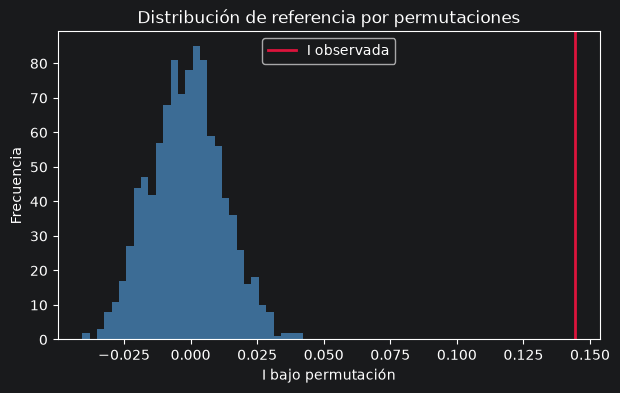

In [8]:
B = 999
rng = np.random.default_rng(2026)
I_permutadas = np.empty(B)
for b in range(B):
    z_perm = rng.permutation(z)
    # Cada fila de W promedia exactamente los K vecinos; evitamos multiplicar
    # la matriz completa en cada iteración, pero la fórmula es la misma.
    rezago_perm = z_perm[vecinos].mean(axis=1)
    I_permutadas[b] = (n / S0) * np.dot(z_perm, rezago_perm) / denominador

p_positiva = (1 + np.count_nonzero(I_permutadas >= I_observada)) / (B + 1)
print(f"I observada: {I_observada:.4f}")
print(f"Media de las permutaciones: {I_permutadas.mean():.4f}")
print(f"Referencia -1/(n-1): {-1 / (n - 1):.4f}")
print(f"p unilateral para asociación positiva: {p_positiva:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(I_permutadas, bins=30, color="steelblue", alpha=0.8)
ax.axvline(I_observada, color="crimson", lw=2, label="I observada")
ax.set(xlabel="I bajo permutación", ylabel="Frecuencia",
       title="Distribución de referencia por permutaciones")
ax.legend()
plt.show()

## 9. Lectura y límites de esta primera iteración

La **I observada** resume si las tasas municipales parecidas se concentran según estos ocho vecinos. Si el valor p unilateral es pequeño, la I positiva observada es poco habitual entre las reubicaciones aleatorias probadas. Eso no identifica focos concretos ni establece qué produjo el patrón.

Antes de usar el resultado en un análisis final conviene revisar: años alternativos, sensibilidad a $k$, tasas inestables en municipios con poca población, el efecto de valores extremos y del subregistro, otra definición de ubicación o vecindad, y qué hacer con municipios sin tasa. El punto interior de un polígono es una aproximación espacial, especialmente para municipios extensos o multipartes. Un Moran local sería un análisis posterior y distinto del Moran **global** calculado aquí.

## 10. Conclusiones de los resultados

- En **2025**, los **1.103 municipios** incluidos presentan una $I$ de Moran global de **0,1445** con ocho vecinos más cercanos y pesos normalizados por fila. El signo positivo indica que, bajo esta vecindad, los municipios con tasas por encima o por debajo de la media tienden a tener vecinos con tasas en el mismo sentido.
- En **999 permutaciones**, ninguna alcanzó la $I$ observada. El valor $p$ unilateral fue **0,001**, el mínimo resoluble con este número de permutaciones; la media permutada fue **−0,0014**, cercana a la referencia teórica **−0,0009**. Hay evidencia de asociación espacial positiva global frente a esa reasignación aleatoria, condicionada a los datos y a la matriz $W$.
- El resultado describe el conjunto de municipios; **no localiza conglomerados**, no mide el efecto de la vacunación ni demuestra que la proximidad cause tasas similares. Su magnitud puede cambiar si se modifica el año, la tasa, la ubicación representativa o la definición de vecinos.